Only for use in "introductory course mathematics" (TUM/CIT/CS, M. Luttenberger)

# Part 2: Polynomial and rational functions

## Polynomial functions

In [5]:
from typing import *
from numbers import Number
import math

Coeffs = Sequence[Number]

def poly_str(a: Coeffs) -> str:
  return '+'.join(f'{ai}X^{i}' for i, ai in enumerate(a)) if len(a) else "0"

def poly_deg(a: Coeffs) -> int:
  d = len(a) - 1
  while d >= 0 and a[d] == 0: d -= 1
  return d

a = (-1,0,1)
print(f"a={poly_str(a)}, deg(a)={poly_deg(a)}")

a=-1X^0+0X^1+1X^2, deg(a)=2


In [7]:
!pip install matplotlib

     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     --------- ---------------------------- 20.5/80.3 kB 330.3 kB/s eta 0:00:01
     ----------------------------- -------- 61.4/80.3 kB 656.4 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 560.2 kB/s eta 0:00:00
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/132.6 kB ? eta -:--:--
     -------------------------------------- 132.6/132.6 kB 7.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB 8.0 MB/s eta 0:00:02
   --- ------------------------------------ 0.8/9.3 MB 9.6 MB/s eta 0:00:01
   ------- -------------------------------- 1.6/9.3 MB 13.0 MB/s eta 0:00:01
   ----------- ---------------------------- 2.6/9.3 MB 15.1 MB/s eta 0:00:01
   -------------- ------------------------- 3.4/9.3 MB 15.7 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\kilia\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


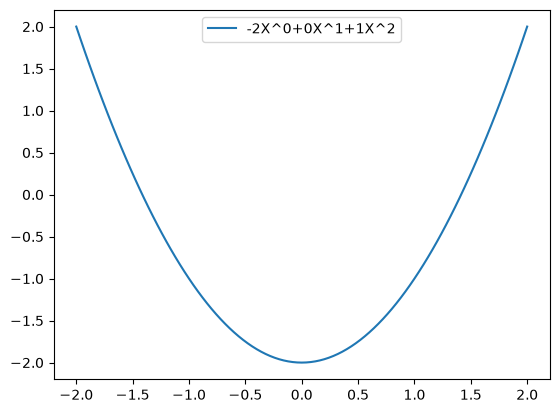

In [8]:
def poly_eval_simple(a: Coeffs, x: Number) -> Number:
  return sum(ai*x**i for i, ai in enumerate(a))

poly_eval = poly_eval_simple

import matplotlib.pyplot as plt
# plots multiple polynomials given as a sequence (in contrast to slides)
def poly_plot(cs: Sequence[Coeffs], xmin, xmax, nsteps=100):
  xs = [xmin+i*((xmax-xmin)/nsteps) for i in range(nsteps+1)]
  for c in cs:
    ys = [poly_eval(c,x) for x in xs]
    plt.plot(xs,ys,label=poly_str(c))
  plt.legend()
  plt.show()

poly_plot([(-2,0,1)], -2, 2, nsteps=100)

### Exercises: Horner's method and bisection

- Optional: Implement `poly_eval_horner` which should use [Horner's method](https://en.wikipedia.org/wiki/Horner%27s_method) to more evaluate a polynomial more
efficiently.
- Optional: Update `poly_str` so that the output is easier to read for a human. E.g. replace `"+-"` by `"-"` and `"X^0"` by `""` and `"+1X"` by `"+X"` and `"-1X"` by `"-X"`.
- Implement `poly_bisection(a,xmin,xmax,eps)` to search for a zero of the polynomial `a` in the interval `[xmin,xmax]` by recursively "bisecting" the interval until either a zero is found or the length of the inteval less than `eps`.
- Optional: Ask Gemini
  > Please make a copy of `poly_biscetion` and extend this copy with code which plots the function represented by the polynomial with coefficients `a` over the interval defined by `xmin` and `xmax` and also plots the approximations computed iteratively.

In [ ]:
def poly_eval_horner(a: Coeffs, x: Number) -> Number:
  ...

# poly_eval = poly_eval_horner

In [ ]:
# Optional improve `def poly_str(a: Coeffs) -> str:`

print(poly_str((-1,0,1)),poly_str((1,0,1)),poly_str((0,-1,1)))  

In [ ]:
def poly_bisection(a: Coeffs, xmin: Number, xmax: Number, eps=1e-9) -> Optional[Number]:
  xl = xmin                 # lower
  xu = xmax                 # upper
  yl = poly_eval(a, xl)
  yu = poly_eval(a, xu)
  if yl > yu:               # we swap so that $y_l= a(x_l)\le a(x_u)=y_u$
    yl, yu = yu, yl
    xl, xu = xu, xl
  ...

In [ ]:
for n in [2,3,5]:
  print(f"sqrt of n={n}")
  print(f"{poly_bisection((-n,0,1), 0, 3, eps=1e-9)} (bisection for eps=10^-9)")
  print(f"{poly_bisection((-n,0,1), 0, 3, eps=1e-15)} (bisection for eps=10^-15)")
  # eps=1e-16 wont' terminate as Python's float (actually a double) is to imprecise
  print(f"{math.sqrt(n)} (math.sqrt)")

### Exercises: addition and multiplication

- Implement `poly_add` and `poly_mul`.

In [ ]:
# For convenience
def poly_neg(a: Coeffs) -> Coeffs:
  return tuple(-ai for ai in a)

In [ ]:
def poly_add(a: Coeffs, b: Coeffs) -> Coeffs:
  ...

print(poly_add((1,-2),(-1,1)))
print(poly_add((1,-1),(-1,1)))
print(poly_add((2,-1),(-1,1)))
print(poly_add((1,0,1,0),(0,1,0,1)))

In [ ]:
def poly_mul(a: Coeffs, b: Coeffs) -> Coeffs:
  ...

print(poly_mul((1,1,1,1,1,1),(-1,1)))
print(poly_mul((1,2,3,4,5,6),(1,2,3,4,5,6)))  # LC 36

In [ ]:
# Binomial theoerm
a = (1,1)  # 1 + X
binom = a
for k in range(1,9):
  print(f"(1+X)^{k} = {poly_str(binom)}")
  print(f"Expected: {poly_str(tuple(math.comb(k,i) for i in range(k+1)))}")
  binom = poly_mul(binom, a)

### Exercise: Euclidean division and GCD

- Implement `poly_divmod(a,b)`: assuming that `b` is not the zero polynomial it should return (the coefficients of) the polynomials `s,r` s.t. `a=sb+r` with `poly_deg(r)<poly_deg(b)`.
  > Recall the implementation of `divmodN`.
- Implement `poly_gcd(a,b)`: it should return (the coefficients of) **a** GCD `d` so that `d` divides `a` and `b` and `d` has the maximal degree.
  > Recall the implementation of `gcdN`. If you like, you can normalize the LC of the GCD to be $1$ in order to make it unique.
- Use your code to compute a GCD of $1+2X-2X^3+X^4$ and $1-X-X^4+X^5$ and then divide both polynomials by it.

In [ ]:
from fractions import Fraction

def poly_divmod(a: Coeffs, b: Coeffs) -> tuple[Coeffs, Coeffs]:
  ...

# For convenience
def poly_div(a: Coeffs, b: Coeffs) -> Coeffs:
  return poly_divmod(a,b)[0]

def poly_mod(a: Coeffs, b: Coeffs) -> Coeffs:
  return poly_divmod(a,b)[1]

In [ ]:
poly_divmod((1,0,1),(1,1))

In [ ]:
poly_divmod((1,2,1),(1,1))

In [ ]:
poly_divmod((1,2,1),(2,2))

In [ ]:
def poly_gcd(a: Coeffs, b: Coeffs) -> Coeffs:
  ...

In [ ]:
poly_gcd((1,2,1),(-1,0,1))

In [ ]:
a = (-1,2,0,-2,1)
b = (1,-1,0,0,-1,1)
d = poly_gcd(a,b)
print(f"a={poly_str(a)}, b={poly_str(b)}, d={poly_str(d)}")
sa, ra = poly_divmod(a,d)
sb, rb = poly_divmod(b,d)
print(f"a=({poly_str(sa)},{poly_str(ra)})")
print(f"b=({poly_str(sb)},{poly_str(rb)})")

## Rational functions

In [ ]:
type PF = tuple[Coeffs, Coeffs]

def pf_str(a: PF) -> str:
  return f"({poly_str(a[0])})/({poly_str(a[1])})"

def pf_eval(a: PF, x: Number) -> Number:
  return poly_eval(a[0],x)/poly_eval(a[1],x)

def pf_plot(pfs: Sequence[PF], xmin: Number, xmax: Number, nsteps: int=100):
  xs = [xmin+i*(xmax-xmin)/nsteps for i in range(nsteps+1)]
  for c in pfs:
    ys = [pf_eval(c,x) for x in xs]
    plt.plot(xs,ys,label=pf_str(c))
  plt.legend()
  plt.show()

### Exercises: Standard operations on polynomial fractions

Use `poly_add`, `poly_mul`, `poly_gcd` and `poly_divmod` to implement
- `pf_add` which adds two polynomial fractions using $\tfrac{a}{b}+\tfrac{c}{d}=\tfrac{ac+bd}{bd}$.
- `poly_mul` which multiplies two polynomial fractions using $\tfrac{a}{b}\cdot\tfrac{c}{d}=\tfrac{ac}{bd}$.
- `pf_cancel` which returns $\tfrac{a/\gcd(a,b)}{b/\gcd(a,b)}$.


In [ ]:
def pf_add(a: PF, b: PF) -> PF:
  ...

def pf_mul(a: PF, b: PF) -> PF:
  ...

def pf_cancel(a: PF) -> PF:
  ...

In [ ]:
p = ((-1,2,0,-2,1),(1,-1,0,0,-1,1))
p = pf_cancel(p)
pf_plot([p], -2, 2)  # w/o canceling or excluding -1 and 1 this will lead to a division by zero

### Exercises: derivative and local exterma of rational functions

- Implement functions `poly_diff` and `pf_diff` which compute the coefficients resp. polynomial fraction reprsenting the derivative.
  > Recall: if $f=\tfrac{p}{q}$, then $f'=\tfrac{p'}{q} - f \cdot \tfrac{q'}{q}$
- Implement a function `pf_find_local_optimum`
which uses bisection to search for a local extremum of a given rational function $f(x)=\tfrac{p(x)}{q(x)}$ within a given interval $[x_l,x_r]$.
 > Recall, if $f$ has a local extremum at $x_0$, then necessarily $f'(x_0)=0$.\\[1mm]
 > To decide if $x_0$ is indeed a local maximum or minimum, while $f^{(i)}(x_0)=0$, try to compute $f^{(i+1)}(x_0)$ until either undefined or nonzero.
 > In the later case $f(x)$ behaves locally at $x_0$ as $f(x_0)+\tfrac{f^{(i+1)}(x_0)}{(i+1)!} \cdot (x-x_0)^{i+1}$.

In [ ]:
# Reminder: (p/q)' = (p'/q) - (p/q) * (q'/q)

def poly_diff(a: Coeffs) -> Coeffs:
  ...

def pf_diff(a: PF) -> PF:
  ...

In [ ]:
p = ((-1,2,0,-2,1),(1,-1,0,0,-1,1))
p = pf_cancel(p)
dp = pf_diff(p)
dp = pf_cancel(dp)
pf_plot([p,dp], -2, 2)
# approximate root of dp close to -0.5 (only numerator polynomial matters)
# x0 = poly_newton(dp[0],-0.5)
x0 = poly_bisection(dp[0],-0.4,-0.5)
print(f"approximated root of first derivative x0={x0} (precise solution: 1-sqrt(2)={1-math.sqrt(2)})")
d2p = pf_diff(dp)
d2p = pf_cancel(d2p)
print(f"second derivative at x0: {pf_eval(d2p,x0)}")
taylor = (-x0,1)
taylor = poly_mul(taylor,taylor)
taylor = poly_mul(taylor,(pf_eval(d2p,x0),))
taylor = poly_add(taylor,(pf_eval(p,x0),))
pf_plot([p,(taylor,(1,))],x0-0.5,x0+0.5)

In [ ]:
def pf_find_local_extremum(f: PF, xl: Number, xu: Number, eps=1e-9) -> Optional[Number]:
  print(f"f={pf_str(f)}")
  f = pf_cancel(f)
  print(f"f={pf_str(f)} after canceling")
  df = pf_diff(f)
  print(f"f'={pf_str(df)} (first derivative)")
  if xl > xu: xu, xl = xl, xu
  ...


In [ ]:
p = ((-1,2,0,-2,1),(1,-1,0,0,-1,1))
pf_find_local_extremum(p,-2,2)

In [ ]:
p = ((-1,2,0,-2,1),(1,-1,0,0,-1,1))
pf_find_local_optimum(p,0,3)

### Exercise: Newton's method

[Newton's method](https://en.wikipedia.org/wiki/Newton%27s_method) is an alternative to bisection in order to compute a zero of a function which usually converges much faster.

It approximates a function $f$ at some $x_i$ by means of the tangent $t_i(x)=f'(x_i)\cdot(x-x_i) + f(x_i)$ at $f$ in $(x_i,f(x_i))$ and use the zero of $t_i(x)$ as next approximation $x_{i+1}$.

> As Newton's method requires a sufficiently good initial approximation of a zero, it is often used in combination with bisection.

- Implement `poly_newton` which takes the coefficients `a` of a polynomial and an initial approximation `x0` as input and then uses Newton's method to improve the initial approximation for up to `100` iterations or `a` evaluates at the current approximation to a value less than `1e-9` ($10^{-9}$)
- Alternatively ask Gemini to do this for you.
  > You can also aks Gemini to add some nice visualization of the Newton's method. But this might require to add an interval/domain.



In [ ]:
def poly_newton(a: Coeffs, x0: Number, eps=1e-9, maxsteps=100) -> Optional[Number]:
  ...

In [ ]:
a = (-2,0,1)
poly_plot([a],0,2)
print(poly_bisection(a, 0, 2, eps=1e-12))
print(poly_newton(a,1,eps=1e-12))
print(math.sqrt(2))

In [ ]:
a = (-2,0,0,1)
poly_plot([a],0,2)
print(poly_bisection(a, 0, 2, eps=1e-12))
print(poly_newton(a,1, eps=1e-12))
print(math.pow(2,1/3))

In [ ]:
a = (1,-1,0,0,0,1)
poly_plot([a],-1.2,1)
print(poly_bisection(a, -1.2, 1, eps=1e-12))
print(poly_newton(a,-1, eps=1e-12))

### Exercise: Classes

- Ask Gemini:
> Please, wrap the above functions starting with `pf_` into a class `PolyFraction` which internally stores a pair `p,q` of type `Coeffs` which is meant to represent the polynomial fraction `p/q` in a single variable `X`.
>
> The class should support the standard arithmetic operations `+,-,*,/` also if one argument is of type `Number`.
>
> Further, it should have the following methods:
> - `X` for returning an object which represents the single variable `X`.
> - `cancel` to divide `p,q` by their GCD.
> - `diff` for computing the derivative
> - `__call__` to evaluate the polynomial fraction at the given number.
- Potential follow-up queries:
 > - Please extend the code with an implementation of `__pow__` for exponents of type `int`.
 > - Add some examples on how to use `PolyFraction`. E.g. use some standard examples for the binomial theorem.
 > - Can you please change the implementation of `__pow__` in `PolyFraction` so that it uses repeated squaring?